# IPL Data Analysis and Match Outcome Prediction

**Objective:** Analyze IPL match and ball-by-ball data (2008–2024) to find team and player performance trends, and build a machine learning model to predict the match winner.

**Dataset:** IPL Complete Dataset (2008–2024) from Kaggle: `matches.csv` (1,095 matches) and `deliveries.csv` (260,920 deliveries)

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Google Colab

**Workflow:** Data collection → Data preprocessing → Exploratory data analysis → Train/test split → Model selection → Model training → Evaluation → Prediction

## 1. Data Collection
Load the match-level and ball-by-ball datasets and look at their size.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

print("Matches:", matches.shape, "| Deliveries:", deliveries.shape)
matches.head()

Matches: (1095, 20) | Deliveries: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


## 2. Data Overview
Check column data types and missing values.

In [4]:
matches.info()
print("\nMissing values:")
print(matches.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

## 3. Data Preprocessing
- Extract the season year from the match date
- Standardize renamed franchises (e.g. Delhi Daredevils → Delhi Capitals, Kings XI Punjab → Punjab Kings)
- Remove the city suffix from venue names so the same stadium is counted once
- Drop matches with no result

In [5]:
matches["season"] = pd.to_datetime(matches["date"]).dt.year

team_fix = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}
for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(team_fix)
for col in ["batting_team", "bowling_team"]:
    deliveries[col] = deliveries[col].replace(team_fix)

matches["venue"] = matches["venue"].str.split(",").str[0].str.strip()

matches = matches[matches["winner"].notna()]
matches = matches[matches["result"] != "no result"]

print("Clean matches:", matches.shape[0])

Clean matches: 1090


## 4. Exploratory Data Analysis
### 4.1 Total wins by team

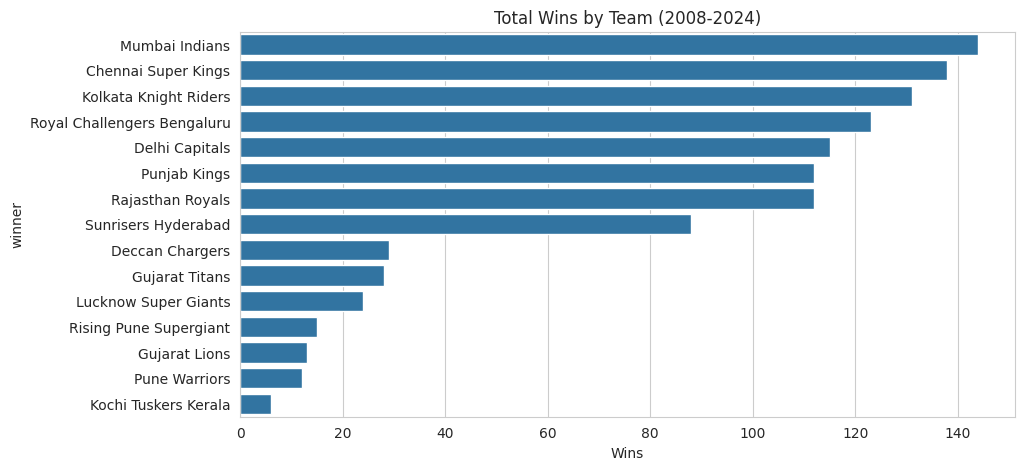

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bengaluru    123
Delhi Capitals                 115
Name: count, dtype: int64


In [6]:
wins = matches["winner"].value_counts()
plt.figure(figsize=(10,5))
sns.barplot(x=wins.values, y=wins.index)
plt.title("Total Wins by Team (2008-2024)")
plt.xlabel("Wins")
plt.show()
print(wins.head())

### 4.2 Toss impact
Does winning the toss help a team win the match?

In [7]:
toss_win = (matches["toss_winner"] == matches["winner"]).mean() * 100
print(f"Toss winner also won the match: {toss_win:.1f}%")

Toss winner also won the match: 50.8%


### 4.3 Batting first vs chasing
Which wins more often: the team batting first or the team chasing?

In [8]:
matches["batting_first"] = np.where(
    matches["toss_decision"] == "bat",
    matches["toss_winner"],
    np.where(matches["toss_winner"] == matches["team1"], matches["team2"], matches["team1"]))

bat_first_win = (matches["batting_first"] == matches["winner"]).mean() * 100
print(f"Batting first win %: {bat_first_win:.1f}%")
print(f"Chasing win %: {100 - bat_first_win:.1f}%")

Batting first win %: 45.9%
Chasing win %: 54.1%


### 4.4 Venue performance
Batting-first win % at venues with 30 or more matches.

In [9]:
venue_wins = matches.groupby("venue").apply(lambda x: (x["batting_first"] == x["winner"]).mean() * 100)
venue_count = matches["venue"].value_counts()
venue_df = pd.DataFrame({"matches": venue_count, "bat_first_win_%": venue_wins})
venue_df[venue_df["matches"] >= 30].sort_values("bat_first_win_%", ascending=False).round(1)

/tmp/ipykernel_1106/2530603887.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  venue_wins = matches.groupby("venue").apply(lambda x: (x["batting_first"] == x["winner"]).mean() * 100)


,matches,bat_first_win_%
venue,,
MA Chidambaram Stadium,85,57.6
Arun Jaitley Stadium,30,53.3
Maharashtra Cricket Association Stadium,35,51.4
Dubai International Cricket Stadium,46,50.0
Dr DY Patil Sports Academy,37,45.9
Feroz Shah Kotla,59,45.8
Wankhede Stadium,118,45.8
M Chinnaswamy Stadium,77,44.2
Rajiv Gandhi International Stadium,77,44.2


### 4.5 Top 10 run scorers

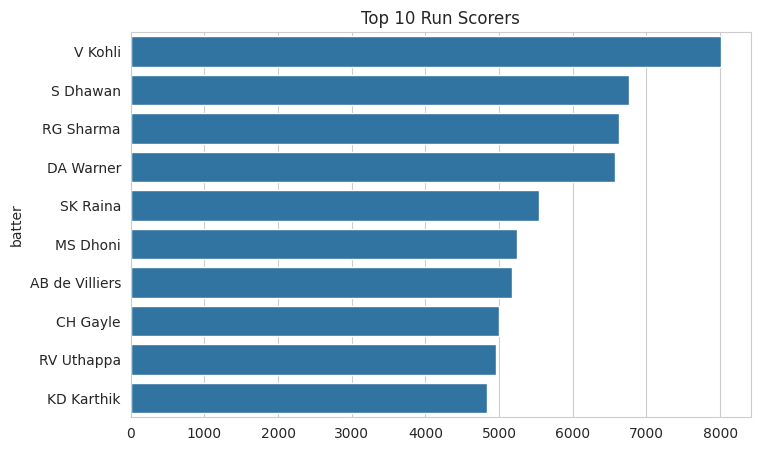

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64


In [10]:
top_bat = deliveries.groupby("batter")["batsman_runs"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,5))
sns.barplot(x=top_bat.values, y=top_bat.index)
plt.title("Top 10 Run Scorers")
plt.show()
print(top_bat)

### 4.6 Top 10 wicket takers
Run outs, retirements and obstructing the field are excluded, as they are not credited to the bowler.

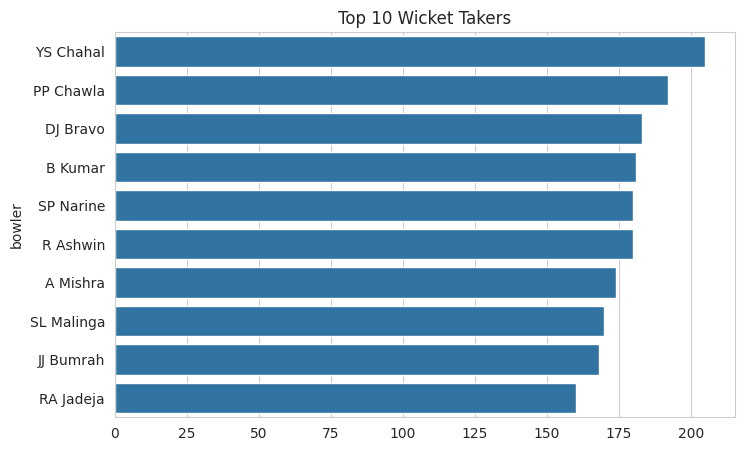

bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
SP Narine     180
R Ashwin      180
A Mishra      174
SL Malinga    170
JJ Bumrah     168
RA Jadeja     160
Name: count, dtype: int64


In [11]:
bowler_wkts = deliveries[(deliveries["is_wicket"] == 1) &
    (~deliveries["dismissal_kind"].isin(["run out", "retired hurt", "retired out", "obstructing the field"]))]
top_bowl = bowler_wkts["bowler"].value_counts().head(10)
plt.figure(figsize=(8,5))
sns.barplot(x=top_bowl.values, y=top_bowl.index)
plt.title("Top 10 Wicket Takers")
plt.show()
print(top_bowl)

### 4.7 Best strike rates (minimum 500 balls faced)
Strike rate = runs / balls faced × 100. Wides are not counted as balls faced.

In [12]:
legal = deliveries[deliveries["extras_type"] != "wides"]
bat = legal.groupby("batter").agg(runs=("batsman_runs", "sum"), balls=("ball", "count"))
bat = bat[bat["balls"] >= 500]
bat["strike_rate"] = (bat["runs"] / bat["balls"] * 100).round(1)
bat.sort_values("strike_rate", ascending=False).head(10)

,runs,balls,strike_rate
batter,,,
AD Russell,2488,1423,174.8
H Klaasen,993,590,168.3
SP Narine,1534,925,165.8
LS Livingstone,939,578,162.5
N Pooran,1769,1092,162.0
RM Patidar,799,503,158.8
GJ Maxwell,2772,1769,156.7
V Sehwag,2728,1755,155.4
Abhishek Sharma,1377,887,155.2


### 4.8 Best death-over economy (overs 16–20, minimum 300 balls)
Overs are zero-indexed in the dataset, so overs 15–19 are the 16th to 20th overs.

In [13]:
death = deliveries[deliveries["over"] >= 15]
runs = death[~death["extras_type"].isin(["byes", "legbyes"])].groupby("bowler")["total_runs"].sum()
balls = death[~death["extras_type"].isin(["wides", "noballs"])].groupby("bowler")["ball"].count()
eco = pd.DataFrame({"runs": runs, "balls": balls}).dropna()
eco = eco[eco["balls"] >= 300]
eco["economy"] = (eco["runs"] / (eco["balls"] / 6)).round(2)
eco.sort_values("economy").head(10)

,runs,balls,economy
bowler,,,
SP Narine,1260,1021,7.40
SL Malinga,1464,1117,7.86
Rashid Khan,692,516,8.05
R Ashwin,807,595,8.14
JJ Bumrah,1723,1247,8.29
DW Steyn,877,634,8.30
PP Chawla,641,444,8.66
CH Morris,933,646,8.67
AR Patel,509,352,8.68


### 4.9 Average first-innings score by season

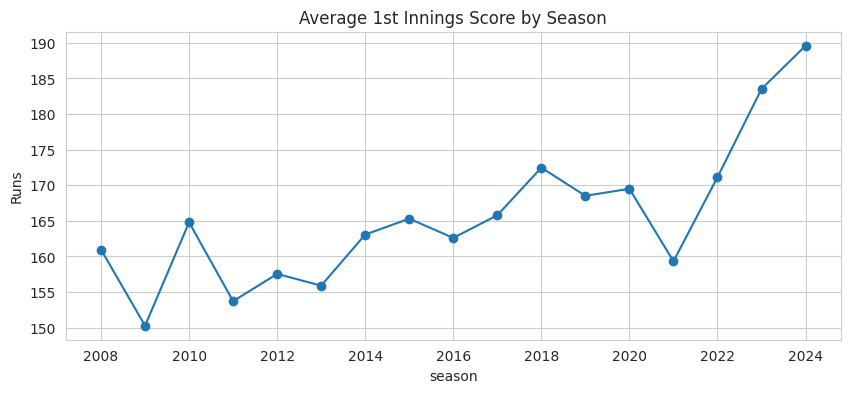

season
2008    161.0
2009    150.3
2010    164.8
2011    153.7
2012    157.5
2013    155.9
2014    163.1
2015    165.3
2016    162.6
2017    165.8
2018    172.5
2019    168.5
2020    169.5
2021    159.3
2022    171.1
2023    183.5
2024    189.6
Name: total_runs, dtype: float64


In [14]:
inn1 = deliveries[deliveries["inning"] == 1].groupby("match_id")["total_runs"].sum().reset_index()
inn1 = inn1.merge(matches[["id", "season"]], left_on="match_id", right_on="id")
avg = inn1.groupby("season")["total_runs"].mean()
avg.plot(marker="o", figsize=(10,4))
plt.title("Average 1st Innings Score by Season")
plt.ylabel("Runs")
plt.show()
print(avg.round(1))

## 5. Feature Engineering and Train/Test Split
**Target:** whether `team1` wins the match (1) or not (0).

**Features:** team1, team2, toss decision, venue (one-hot encoded) and whether team1 won the toss.

The data is split 80% for training and 20% for testing.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

df = matches[["team1", "team2", "toss_winner", "toss_decision", "venue", "winner"]].copy()
df["team1_win"] = (df["winner"] == df["team1"]).astype(int)
df["toss_won_by_team1"] = (df["toss_winner"] == df["team1"]).astype(int)

X = pd.get_dummies(df[["team1", "team2", "toss_decision", "venue"]])
X["toss_won_by_team1"] = df["toss_won_by_team1"]
y = df["team1_win"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

Train: 872 | Test: 218


## 6. Model Training and Evaluation
Train Logistic Regression and Random Forest classifiers and compare them using accuracy and the confusion matrix.

In [16]:
lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train, y_train)

for name, model in [("Logistic Regression", lr), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    print(name, "Accuracy:", round(accuracy_score(y_test, pred) * 100, 1), "%")
    print(confusion_matrix(y_test, pred), "\n")

Logistic Regression Accuracy: 51.8 %
[[57 53]
 [52 56]] 

Random Forest Accuracy: 51.8 %
[[53 57]
 [48 60]] 



## 7. Make Predictions
Use the trained Random Forest model to predict the winner and win probability for a new match.

In [17]:
# Predict the winner of a new match
new_match = pd.DataFrame([{
    "team1": "Mumbai Indians",
    "team2": "Chennai Super Kings",
    "toss_decision": "field",
    "venue": "Wankhede Stadium"
}])
new_X = pd.get_dummies(new_match).reindex(columns=X.columns, fill_value=0)
new_X["toss_won_by_team1"] = 1   # 1 if team1 won the toss, else 0

prob = rf.predict_proba(new_X)[0][1] * 100
winner = new_match["team1"][0] if prob >= 50 else new_match["team2"][0]
print(f"{new_match['team1'][0]} win chance: {prob:.1f}%")
print("Predicted winner:", winner)

Mumbai Indians win chance: 91.5%
Predicted winner: Mumbai Indians


## 8. Key Insights
- **Toss impact:** toss winners won only **50.8%** of matches, so the toss has almost no effect on the result.
- **Chasing advantage:** chasing teams won **54.1%** of matches vs 45.9% for teams batting first.
- **Top run scorer:** **V Kohli** with **8,014** runs.
- **Model performance:** Logistic Regression and Random Forest both reached **51.8%** accuracy on 218 test matches.

## Conclusion
Pre-match features such as teams, toss and venue are not enough to predict IPL results reliably; accuracy stays close to 50%. Match outcomes depend more on player form and in-game conditions.

**Next steps:** add features such as team recent form, head-to-head record and player availability to improve accuracy.